# Задача 5. Лінійна регресія в Python

Дані: `train.csv`, 1460 будинків. `test.csv` не містить ціни, тому для оцінювання не використовується.
Повна модель: `LotFrontage`, `LotArea`, `YearBuilt`, `BsmtFinSF1`, `BsmtUnfSF`, `BedroomAbvGr`, `C(MSSubClass)`.
Рівень значущості — 0.05; seed — 42.

In [1]:
import sys
import importlib.util
import subprocess

if importlib.util.find_spec("sklearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn"])

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import curve_fit, minimize_scalar
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, KFold
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display

SEED, ALPHA = 42, 0.05
DATA = Path("house-prices-advanced-regression-techniques")
if not DATA.exists():
    DATA = Path("lab3") / DATA
assert DATA.exists(), "Не знайдено папку з даними"

sns.set_theme(style="white", context="notebook", palette=["black", "0.5"])
plt.style.use("grayscale")
plt.rcParams.update({"font.family": "DejaVu Serif", "figure.dpi": 115,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "savefig.facecolor": "white"})
pd.set_option("display.max_columns", 10)
pd.set_option("display.precision", 4)
results = {}

`keep_default_na=False` зберігає структурні категорії `NA`. Справжні числові пропуски та пропуск `Electrical` обробляю окремо.

In [2]:
raw = pd.read_csv(DATA / "train.csv", keep_default_na=False)
test = pd.read_csv(DATA / "test.csv", keep_default_na=False)
df = raw.copy()
numeric_missing = ["LotFrontage", "MasVnrArea", "GarageYrBlt"]
for col in numeric_missing:
    df[col] = pd.to_numeric(df[col].replace({"NA": np.nan, "": np.nan}))
df["Electrical"] = df["Electrical"].replace({"NA": np.nan, "": np.nan})

structural = [
    "Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature"
]
assert df[structural].isna().sum().sum() == 0
print(f"train: {df.shape}; test: {test.shape}")
print("Справжні / числові пропуски:")
display(df.isna().sum().loc[lambda s: s > 0].rename("Кількість").to_frame())
display(df[["Id", "MSSubClass", "LotArea", "YearBuilt", "SalePrice"]].head())

train: (1460, 81); test: (1459, 80)
Справжні / числові пропуски:


,Кількість
LotFrontage,259
MasVnrArea,8
Electrical,1
GarageYrBlt,81


,Id,MSSubClass,LotArea,YearBuilt,SalePrice
0,1,60,8450,2003,208500
1,2,20,9600,1976,181500
2,3,60,11250,2001,223500
3,4,70,9550,1915,140000
4,5,60,14260,2000,250000


## (1) Кодування MSSubClass

Ознака номінальна: коди не задають порядку чи відстані. Обираю dummy-кодування з базою 20; з константою потрібно K−1 індикаторів.
Для порядкової шкали є порядок, для кардинальної — змістовні числові різниці.

In [3]:
m_numeric = smf.ols("SalePrice ~ MSSubClass", data=df).fit()
m_factor = smf.ols("SalePrice ~ C(MSSubClass)", data=df).fit()
typed = df.assign(MSSubClass=pd.Categorical(df["MSSubClass"]))
m_typed = smf.ols("SalePrice ~ MSSubClass", data=typed).fit()
assert np.allclose(m_factor.fittedvalues, m_typed.fittedvalues)

display(pd.DataFrame({
    "Кодування": ["int64, як число", "C(MSSubClass)", "pd.Categorical"],
    "Кількість параметрів": [len(m.params) for m in
                             [m_numeric, m_factor, m_typed]],
    "R²": [m.rsquared for m in [m_numeric, m_factor, m_typed]]
}))
print("Тип у CSV:", df["MSSubClass"].dtype)
print("Наявних рівнів:", df["MSSubClass"].nunique())
print("Числова модель:", m_numeric.params.round(3).to_dict())
results.update(r2_num=m_numeric.rsquared, r2_cat=m_factor.rsquared)

,Кодування,Кількість параметрів,R²
0,"int64, як число",2,0.0071
1,C(MSSubClass),15,0.2463
2,pd.Categorical,15,0.2463


Тип у CSV: int64
Наявних рівнів: 15
Числова модель: {'Intercept': 189927.443, 'MSSubClass': -158.29}


Числовий код дає R²=0.007104, категоріальний — 0.246316. `C(...)` і `pd.Categorical` дають однакові прогнози. У train є 15 типів із 16 можливих.

## (2) Діаграми розсіювання

Площі — у кв. футах, фасад — у футах, ціна — у доларах.

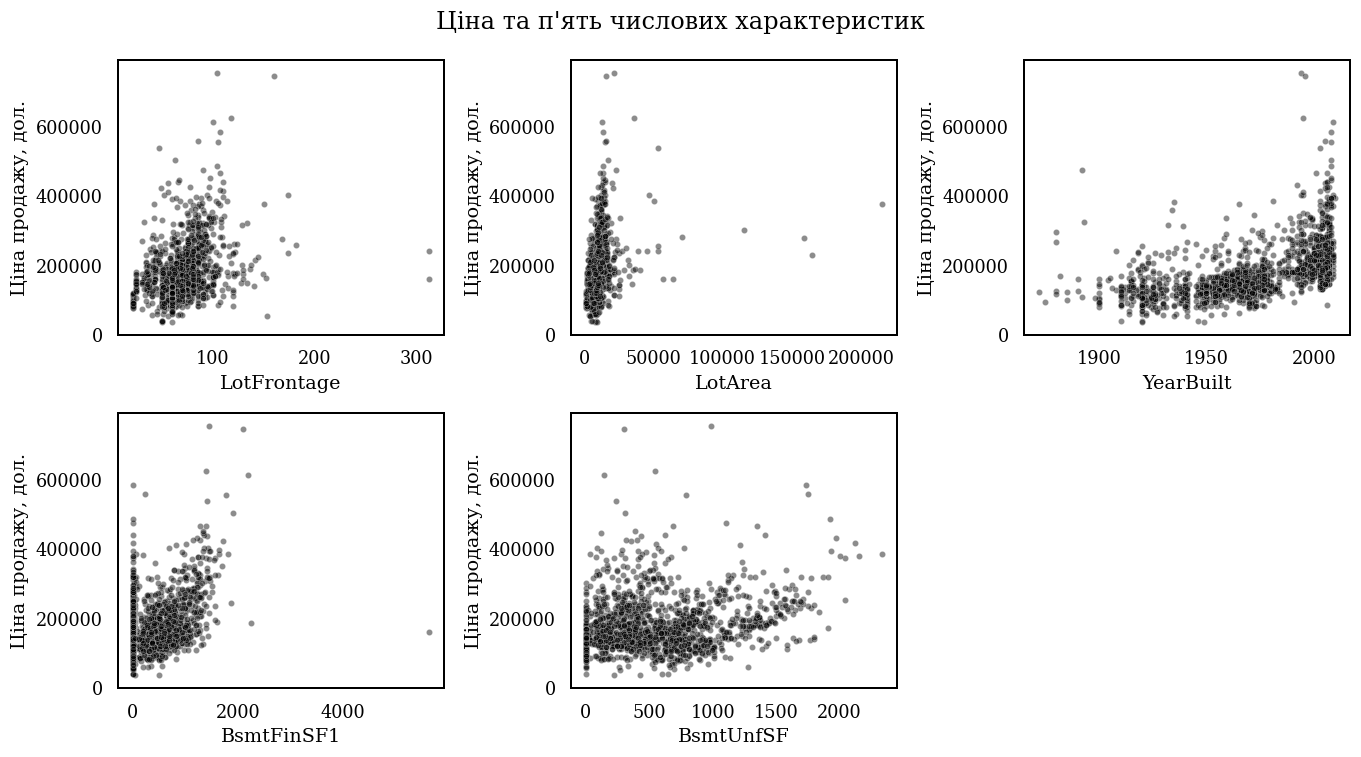

In [4]:
numeric_terms = ["LotFrontage", "LotArea", "YearBuilt",
                 "BsmtFinSF1", "BsmtUnfSF", "BedroomAbvGr"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.7))
for ax, col in zip(axes.flat, numeric_terms[:5]):
    sns.scatterplot(data=df, x=col, y="SalePrice", s=15, alpha=.45, ax=ax)
    ax.set_ylabel("Ціна продажу, дол.")
axes.flat[-1].axis("off")
fig.suptitle("Ціна та п'ять числових характеристик", fontsize=15)
fig.tight_layout()
plt.show()

`LotFrontage`: додатний зв'язок, крайні значення й пропуски; можливий логарифм.
`LotArea`: сильна асиметрія; логарифм і перевірка впливових ділянок.
`YearBuilt`: новіші будинки дорожчі; можливі вік, квадрат або сплайн.
`BsmtFinSF1`: нулі та крайній підвал; можливі `log1p` й індикатор ненульової площі.
`BsmtUnfSF`: слабший зв'язок; можна використати частку завершеного підвалу.

## (3) Проста OLS та повна модель

$P_i=\beta_0+\beta_1 LotArea_i+u_i$.
$H_0:\beta_1=0$, $H_1:\beta_1\ne0$; $t=\widehat\beta_1/SE(\widehat\beta_1)$, df=n−2.

In [5]:
simple = sm.OLS(df["SalePrice"], sm.add_constant(df[["LotArea"]])).fit()
print(simple.summary())
print(f"t вручну = {simple.params['LotArea'] / simple.bse['LotArea']:.6f}")
results.update(simple_b=simple.params["LotArea"],
               simple_se=simple.bse["LotArea"], simple_t=simple.tvalues["LotArea"],
               simple_p=simple.pvalues["LotArea"], simple_r2=simple.rsquared)

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     109.1
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.12e-24
Time:                        20:14:41   Log-Likelihood:                -18491.
No. Observations:                1460   AIC:                         3.699e+04
Df Residuals:                    1458   BIC:                         3.700e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.588e+05   2914.717     54.495      0.0

Нахил — 2.099972, SE — 0.201058, t=10.444633, p=1.12314·10⁻²⁴. Нахил значущий, але R²=0.069613.

$R^2=1-SSE/SST$; $\overline R^2=1-[SSE/(n-k)]/[SST/(n-1)]$, k включає константу.
Скоригований R² штрафує зайві регресори. Для багатофакторного аналізу використовую однакові 1201 повний рядок.

In [6]:
sample = df.dropna(subset=numeric_terms + ["SalePrice", "MSSubClass"]).copy()
formula = "SalePrice ~ " + " + ".join(numeric_terms + ["C(MSSubClass)"])
full = smf.ols(formula, data=sample).fit()
full_log = smf.ols(formula.replace("SalePrice", "np.log(SalePrice)"),
                   data=sample).fit()
X = pd.DataFrame(full.model.exog, columns=full.model.exog_names,
                 index=sample.index)
y = sample["SalePrice"].to_numpy(dtype=float)
print(f"n = {len(sample)}, параметрів = {len(full.params)}")
display(pd.DataFrame({"Коефіцієнт": full.params, "SE": full.bse,
                      "t": full.tvalues, "p": full.pvalues}))
print(f"R² = {full.rsquared:.4f}; скоригований R² = {full.rsquared_adj:.4f}")
results.update(full_r2=full.rsquared, full_adj=full.rsquared_adj)

n = 1201, параметрів = 21


,Коефіцієнт,SE,t,p
Intercept,-2.1258e+06,184270.7147,-11.5362,3.0031e-29
C(MSSubClass)[T.30],1.3561e+04,8636.5637,1.5702,1.1663e-01
C(MSSubClass)[T.40],1.5983e+04,30429.1698,0.5252,5.9951e-01
C(MSSubClass)[T.45],1.8408e+04,15902.3258,1.1576,2.4726e-01
C(MSSubClass)[T.50],3.5020e+04,6540.7188,5.3541,1.0327e-07
C(MSSubClass)[T.60],4.9447e+04,5026.0237,9.8383,5.2628e-22
C(MSSubClass)[T.70],7.9892e+04,9259.8513,8.6277,1.9905e-17
C(MSSubClass)[T.75],9.9315e+04,14935.7683,6.6495,4.4867e-11
C(MSSubClass)[T.80],1.1770e+04,9003.2350,1.3073,1.9136e-01
C(MSSubClass)[T.85],-8.6857e+03,14256.9922,-0.6092,5.4249e-01


R² = 0.6181; скоригований R² = 0.6116


Повна модель: R²=0.618080, скоригований R²=0.611607, 21 параметр. Прогнозну якість перевірю крос-валідацією.

## (4) Спільна значущість MSSubClass

$H_0:\gamma_1=\cdots=\gamma_{14}=0$. Альтернатива — хоча б один коефіцієнт ненульовий.
Порядок параметрів: константа, 14 dummy, 6 числових.
$$R=[0_{14\times1}\ I_{14}\ 0_{14\times6}],\qquad r=0_{14\times1}.$$

In [7]:
dummy_names = [c for c in X if c.startswith("C(MSSubClass)")]
R = np.zeros((len(dummy_names), X.shape[1]))
for row, col in enumerate(dummy_names):
    R[row, X.columns.get_loc(col)] = 1
r = np.zeros(len(dummy_names))
factor_test = full.f_test((R, r))
print("R.shape =", R.shape, "; r =", r.astype(int))
print(factor_test)
factor_hc3 = full.get_robustcov_results(cov_type="HC3").f_test((R, r))
print("Робастний F/Wald HC3:", factor_hc3)
results.update(factor_F=float(factor_test.fvalue), factor_p=float(factor_test.pvalue),
               factor_hc_p=float(factor_hc3.pvalue))

R.shape = (14, 21) ; r = [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
<F test: F=18.137811621118452, p=2.2496306868259754e-41, df_denom=1.18e+03, df_num=14>
Робастний F/Wald HC3: <F test: F=18.553337731229597, p=2.3050954822157267e-42, df_denom=1.18e+03, df_num=14>


F(14,1180)=18.137812, p=2.24963·10⁻⁴¹. Фактор спільно значущий. HC3 дає той самий висновок.

## (5) Інтерпретація параметрів

Ефекти умовні, за інших рівних регресорів; причинність не встановлюється.

In [8]:
first_dummy = dummy_names[0]
interpret = pd.DataFrame({
    "Параметр": ["LotArea", first_dummy, "BedroomAbvGr"],
    "Модель ціни, дол.": full.params[["LotArea", first_dummy, "BedroomAbvGr"]].values,
    "Модель log(ціни)": full_log.params[["LotArea", first_dummy, "BedroomAbvGr"]].values
})
display(interpret)
log_exact = 100 * np.expm1(full_log.params[["LotArea", first_dummy, "BedroomAbvGr"]])
print("Точна зміна геометричного середнього, %:")
display(log_exact.rename("100 × (exp(β) − 1)").to_frame())
results.update(area_b=full.params["LotArea"], bed_b=full.params["BedroomAbvGr"],
               dummy_b=full.params[first_dummy],
               area1000=1000*full.params["LotArea"],
               log_area1000=100*np.expm1(1000*full_log.params["LotArea"]),
               log_bed=log_exact["BedroomAbvGr"], log_dummy=log_exact[first_dummy])

,Параметр,"Модель ціни, дол.",Модель log(ціни)
0,LotArea,1.2395,5.1899e-06
1,C(MSSubClass)[T.30],13561.4903,-6.2684e-02
2,BedroomAbvGr,5338.2016,5.1582e-02


Точна зміна геометричного середнього, %:


,100 × (exp(β) − 1)
LotArea,0.0005
C(MSSubClass)[T.30],-6.0760
BedroomAbvGr,5.2935


Додатковий кв. фут ділянки: +1.239472 дол.; спальня: +5338.201570 дол.
Dummy типу 30 порівнює його з базою 20: +13561.490340 дол. Коефіцієнта базового типу немає; зміна числового коду не є одиницею ефекту.
Порівняння типів 30 і 20 за однакового року побудови потребує екстраполяції.

У log-моделі зміна геометричного середнього: $100(e^{\beta\Delta x}-1)\%$.
1000 кв. футів: +0.5203%; спальня: +5.2935%; тип 30 щодо 20: −6.0760%.

## (6) Довірчий інтервал та нормальність

95% інтервал: $\widehat\beta_j\pm t_{0.975,n-k}SE(\widehat\beta_j)$.
Перевіряю нормальність залишків і сталу дисперсію.

,Метод,Нижня межа,Верхня межа
0,Класичний,0.8198,1.6591
1,HC3,-0.4490,2.9279


Jarque–Bera: JB=40747.994, p=0
Shapiro–Wilk: W=0.7970, p=2.83e-36
Бройш–Паган: LM=410.215, p=1.55e-74


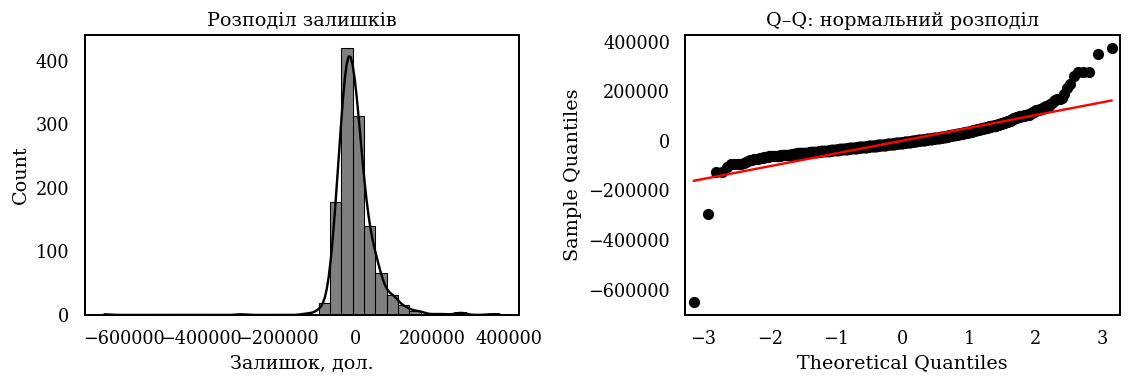

In [9]:
ci = full.conf_int(alpha=ALPHA).loc["LotArea"]
hc3 = full.get_robustcov_results(cov_type="HC3")
j = full.model.exog_names.index("LotArea")
ci_hc3 = hc3.conf_int(alpha=ALPHA)[j]
jb = stats.jarque_bera(full.resid)
shapiro = stats.shapiro(full.resid)
bp = het_breuschpagan(full.resid, full.model.exog)
display(pd.DataFrame({"Метод": ["Класичний", "HC3"],
                      "Нижня межа": [ci.iloc[0], ci_hc3[0]],
                      "Верхня межа": [ci.iloc[1], ci_hc3[1]]}))
print(f"Jarque–Bera: JB={jb.statistic:.3f}, p={jb.pvalue:.3g}")
print(f"Shapiro–Wilk: W={shapiro.statistic:.4f}, p={shapiro.pvalue:.3g}")
print(f"Бройш–Паган: LM={bp[0]:.3f}, p={bp[1]:.3g}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(full.resid, bins=35, kde=True, ax=axes[0])
axes[0].set(xlabel="Залишок, дол.", title="Розподіл залишків")
sm.qqplot(full.resid, line="s", ax=axes[1])
axes[1].set_title("Q–Q: нормальний розподіл")
plt.tight_layout()
plt.show()
results.update(ci_low=ci.iloc[0], ci_high=ci.iloc[1],
               hc_low=ci_hc3[0], hc_high=ci_hc3[1],
               jb_p=jb.pvalue, shapiro_p=shapiro.pvalue, bp_p=bp[1])

Класичний інтервал LotArea: [0.819819; 1.659125] дол. за кв. фут. Він не містить нуля — класичний t-тест значущий.
HC3: [−0.448993; 2.927938], містить нуль; висновок чутливий до оцінки похибок.
Нормальність і сталу дисперсію відхилено. Нормальність не потрібна для обчислення OLS, але важлива для точних класичних t/F-висновків.

## (7) Покроковий відбір за BIC

Починаю з повної моделі. Вилучаю групу, що найбільше зменшує $BIC=n\log(SSE/n)+k\log n+const$; зупиняюся без поліпшення.
MSSubClass вилучається всією групою. Константа й вибірка незмінні. Центрування та матриця X'X прискорюють обчислення.
Алгоритм жадібний, глобальний мінімум не гарантований.

In [10]:
groups = {name: [name] for name in numeric_terms}
groups["MSSubClass"] = dummy_names

def backward_bic(X_train, y_train, group_columns):
    a = X_train.to_numpy(dtype=float)
    mu, scale = a.mean(axis=0), a.std(axis=0)
    mu[0], scale[0] = 0, 1
    scale[scale == 0] = 1
    a = (a - mu) / scale
    b = np.asarray(y_train, dtype=float)
    b = b - b.mean()
    gram, xy, yy = a.T @ a, a.T @ b, b @ b
    names, n = list(X_train.columns), len(b)

    def evaluate(active):
        cols = ["Intercept"] + [c for c in names[1:]
                                if any(c in group_columns[g] for g in active)]
        ix = [names.index(c) for c in cols]
        G, v = gram[np.ix_(ix, ix)], xy[ix]
        coef = np.linalg.lstsq(G, v, rcond=1e-12)[0]
        rss = max(float(yy - v @ coef), np.finfo(float).eps)
        k = np.linalg.matrix_rank(G)
        return n * np.log(rss / n) + k * np.log(n), cols

    active = list(group_columns)
    bic, cols = evaluate(active)
    history = [{"Крок": 0, "Вилучено": "—", "BIC без сталої": bic,
                "Параметрів": len(cols)}]
    while active:
        candidates = [(evaluate([g for g in active if g != drop])[0], drop)
                      for drop in active]
        best, drop = min(candidates)
        if best >= bic - 1e-8:
            break
        active.remove(drop)
        bic, cols = evaluate(active)
        history.append({"Крок": len(history), "Вилучено": drop,
                        "BIC без сталої": bic, "Параметрів": len(cols)})
    return cols, pd.DataFrame(history), bic

selected_cols, history, bic_reduced = backward_bic(X, y, groups)
selected = sm.OLS(y, X[selected_cols]).fit()
selected_log = sm.OLS(np.log(y), X[selected_cols]).fit()
assert np.isclose(selected.bic,
                  bic_reduced + len(y) * (1 + np.log(2 * np.pi)))
display(history)
comparison = pd.DataFrame({
    "Модель": ["Повна", "Після BIC"],
    "Параметрів": [len(full.params), len(selected.params)],
    "R²": [full.rsquared, selected.rsquared],
    "Скоригований R²": [full.rsquared_adj, selected.rsquared_adj],
    "AIC": [full.aic, selected.aic], "BIC": [full.bic, selected.bic]
})
display(comparison)
print("Залишено:", [g for g, cols in groups.items()
                     if any(c in selected_cols for c in cols)])
results.update(selected_r2=selected.rsquared, selected_bic=selected.bic,
               full_bic=full.bic, selected_k=len(selected.params))

,Крок,Вилучено,BIC без сталої,Параметрів
0,0,—,26209.6227,21
1,1,LotFrontage,26206.1101,20
2,2,BedroomAbvGr,26204.8452,19


,Модель,Параметрів,R²,Скоригований R²,AIC,BIC
0,Повна,21,0.6181,0.6116,29511.0039,29617.9130
1,Після BIC,19,0.6151,0.6092,29516.4082,29613.1355


Залишено: ['LotArea', 'YearBuilt', 'BsmtFinSF1', 'BsmtUnfSF', 'MSSubClass']


Вилучено LotFrontage та BedroomAbvGr. BIC: 29617.913031 → 29613.135520; R²: 0.618080 → 0.615078.
Залишено 19 параметрів. Цю специфікацію використовую далі; звичайні p-значення не враховують попереднього відбору.

## (8) Викиди та вплив

$$h_i=x_i'(X'X)^{-1}x_i,\qquad D_i=\frac{\widehat u_i^2}{k\widehat\sigma^2}\frac{h_i}{(1-h_i)^2}.$$
Важіль описує незвичність регресорів, Кук — вплив на оцінки. Пороги 2k/n та 4/n — орієнтири перевірки.

,Id,Залишок,Студентизований залишок,Важіль,Кук
1298,1299,-638582.2931,-13.6005,0.1887,2.2649
313,314,-96858.4814,-3.1161,0.6445,0.9264
185,186,279581.2821,5.5650,0.0712,0.1249
523,524,-299751.1486,-5.8537,0.0351,0.0656
1182,1183,362218.7463,7.0192,0.0200,0.0530
691,692,375397.6987,7.2619,0.0166,0.0469
583,584,131988.7276,2.6259,0.0703,0.0274
898,899,276297.5072,5.3427,0.0158,0.0241


Найбільший важіль:


,Значення
Id,314
MSSubClass,20
LotArea,215245
LotFrontage,150.0
YearBuilt,1965
BsmtFinSF1,1236
BsmtUnfSF,80
SalePrice,375000


Понад 2k/n: 88 рядків
Понад 4/n: 49 рядків
Кількість будинків цього типу: 437


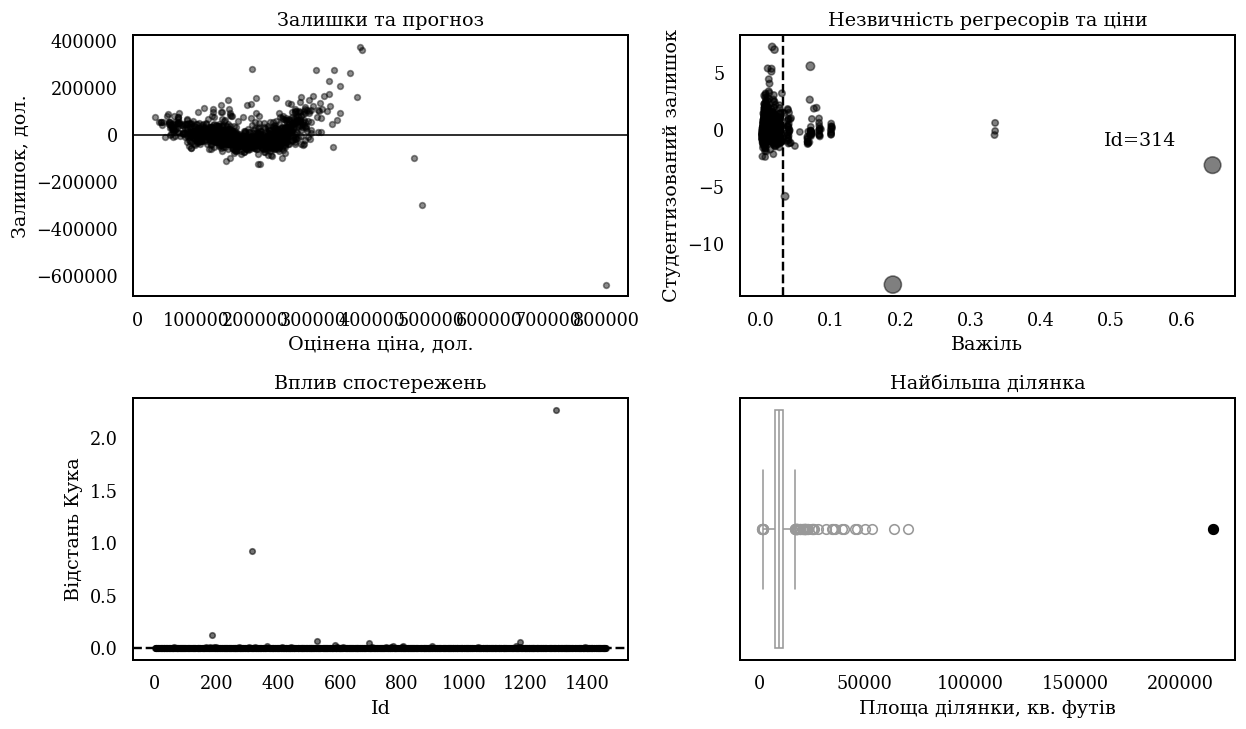

,З усіма рядками,Без найбільшого важеля
LotArea,1.3598,2.2237
YearBuilt,1064.2054,1074.4617
BsmtFinSF1,91.7215,87.5936
BsmtUnfSF,72.1393,69.1693


In [11]:
influence = OLSInfluence(selected)
n, k = len(y), len(selected.params)
diag = pd.DataFrame({
    "Id": sample["Id"], "Залишок": selected.resid,
    "Студентизований залишок": influence.resid_studentized_internal,
    "Важіль": influence.hat_matrix_diag,
    "Кук": influence.cooks_distance[0]
}, index=sample.index)
display(diag.nlargest(8, "Кук").round(4))
max_idx = diag["Важіль"].idxmax()
max_row = sample.loc[max_idx]
print("Найбільший важіль:")
display(max_row[["Id", "MSSubClass", "LotArea", "LotFrontage",
                 "YearBuilt", "BsmtFinSF1", "BsmtUnfSF", "SalePrice"]].to_frame("Значення"))
print(f"Понад 2k/n: {(diag['Важіль'] > 2*k/n).sum()} рядків")
print(f"Понад 4/n: {(diag['Кук'] > 4/n).sum()} рядків")
print("Кількість будинків цього типу:",
      int(sample["MSSubClass"].value_counts().loc[max_row["MSSubClass"]]))

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
axes[0, 0].scatter(selected.fittedvalues, selected.resid, s=13, alpha=.45)
axes[0, 0].axhline(0, color="black", lw=1)
axes[0, 0].set(xlabel="Оцінена ціна, дол.", ylabel="Залишок, дол.",
               title="Залишки та прогноз")
axes[0, 1].scatter(diag["Важіль"], diag["Студентизований залишок"],
                    s=15 + 100 * np.minimum(diag["Кук"], 1), alpha=.5)
axes[0, 1].axvline(2*k/n, ls="--", color="black")
axes[0, 1].set(xlabel="Важіль", ylabel="Студентизований залишок",
               title="Незвичність регресорів та ціни")
axes[0, 1].annotate(f"Id={int(max_row['Id'])}",
                    (diag.loc[max_idx, "Важіль"],
                     diag.loc[max_idx, "Студентизований залишок"]),
                    xytext=(-68, 12), textcoords="offset points")
axes[1, 0].scatter(sample["Id"], diag["Кук"], s=12, alpha=.55)
axes[1, 0].axhline(4/n, ls="--", color="black")
axes[1, 0].set(xlabel="Id", ylabel="Відстань Кука", title="Вплив спостережень")
sns.boxplot(x=sample["LotArea"], ax=axes[1, 1], color="white")
axes[1, 1].scatter([max_row["LotArea"]], [0], color="black", zorder=5)
axes[1, 1].set(xlabel="Площа ділянки, кв. футів", title="Найбільша ділянка")
plt.tight_layout()
plt.show()

keep = sample.index != max_idx
sensitivity = sm.OLS(y[keep], X.loc[keep, selected_cols]).fit()
display(pd.DataFrame({"З усіма рядками": selected.params,
                      "Без найбільшого важеля": sensitivity.params})
        .loc[["LotArea", "YearBuilt", "BsmtFinSF1", "BsmtUnfSF"]])
results.update(max_id=int(max_row["Id"]), max_area=max_row["LotArea"],
               median_area=sample["LotArea"].median(),
               max_h=diag.loc[max_idx, "Важіль"], max_cook=diag.loc[max_idx, "Кук"],
               selected_area=selected.params["LotArea"],
               sensitivity_area=sensitivity.params["LotArea"])

Найбільший важіль — Id=314: h=0.644460, D=0.926359. Площа 215245 кв. футів проти медіани 9262; тип 20 поширений.
Без цього рядка коефіцієнт LotArea змінюється з 1.359764 до 2.223689. Основну модель не змінюю: помилку в даних не підтверджено.

## (9) Два способи імпутації

Беру всі 1460 рядків і 79 характеристик без Id та ціни. Приховую п'ять випадкових LotArea.
Метод 1 — медіана: стійка до великих ділянок.
Метод 2 — IterativeImputer: $x_j=a_j+X_{-j}b_j+\varepsilon_j$, Bayesian Ridge та послідовне оновлення пропусків.
Категорії кодуються індикаторами; структурні NA зберігаються. За відсутності гаража його рік кодую нулем, справжній пропуск Electrical — модою.

In [12]:
rng = np.random.default_rng(SEED)
hidden = rng.choice(df.index.to_numpy(), size=5, replace=False)
truth = df.loc[hidden, "LotArea"].astype(float).copy()
work = df.drop(columns=["Id", "SalePrice"]).copy()
work["MSSubClass"] = work["MSSubClass"].astype(str)
work.loc[hidden, "LotArea"] = np.nan
no_garage = (work["GarageType"] == "NA") & work["GarageYrBlt"].isna()
work.loc[no_garage, "GarageYrBlt"] = 0
num_cols = work.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in work if c not in num_cols]

cat_filled = work[cat_cols].copy()
for col in cat_cols:
    cat_filled[col] = cat_filled[col].fillna(cat_filled[col].mode().iloc[0])

median_imputer = SimpleImputer(strategy="median")
median_numeric = pd.DataFrame(median_imputer.fit_transform(work[num_cols]),
                              columns=num_cols, index=work.index)
median_filled = work.copy()
median_filled[num_cols] = median_numeric
median_filled[cat_cols] = cat_filled

scaler = StandardScaler()
z_num = scaler.fit_transform(work[num_cols])
z_cat = pd.get_dummies(cat_filled, dtype=float).to_numpy()
all_features = np.column_stack([z_num, z_cat])
lower = np.full(all_features.shape[1], -np.inf)
area_j = num_cols.index("LotArea")
lower[area_j] = (1 - scaler.mean_[area_j]) / scaler.scale_[area_j]
iter_imputer = IterativeImputer(
    max_iter=30, tol=0.01, skip_complete=True,
    initial_strategy="median", random_state=SEED, min_value=lower
)
z_filled = iter_imputer.fit_transform(all_features)
iter_numeric = pd.DataFrame(scaler.inverse_transform(z_filled[:, :len(num_cols)]),
                            columns=num_cols, index=work.index)
iter_filled = work.copy()
iter_filled[num_cols] = iter_numeric
iter_filled[cat_cols] = cat_filled

for completed in [median_filled, iter_filled]:
    assert completed.isna().sum().sum() == 0
    assert completed[structural].equals(work[structural])
    for col in num_cols:
        observed = work[col].notna()
        assert np.allclose(completed.loc[observed, col], work.loc[observed, col])

imputation = pd.DataFrame({
    "Id": df.loc[hidden, "Id"], "Справжня площа": truth,
    "Медіана": median_filled.loc[hidden, "LotArea"],
    "Ітеративна": iter_filled.loc[hidden, "LotArea"]
})
display(imputation.round(2).reset_index(drop=True))
imp_metrics = []
for label in ["Медіана", "Ітеративна"]:
    error = imputation[label] - truth
    imp_metrics.append({"Метод": label, "MAE, кв. футів": np.abs(error).mean(),
                        "RMSE, кв. футів": np.sqrt(np.mean(error**2))})
display(pd.DataFrame(imp_metrics).round(2))
print("Ітерацій:", iter_imputer.n_iter_)
print("Початкових характеристик:", work.shape[1],
      "; після dummy-кодування:", all_features.shape[1])
results.update(imp_median_rmse=imp_metrics[0]["RMSE, кв. футів"],
               imp_iter_rmse=imp_metrics[1]["RMSE, кв. футів"])

,Id,Справжня площа,Медіана,Ітеративна
0,1128,14572.0,9477.0,38400.75
1,641,12677.0,9477.0,5804.81
2,955,9400.0,9477.0,1.00
3,130,8973.0,9477.0,7296.40
4,633,11900.0,9477.0,11325.16


,Метод,"MAE, кв. футів","RMSE, кв. футів"
0,Медіана,2259.80,2909.64
1,Ітеративна,8470.28,11887.13


Ітерацій: 3
Початкових характеристик: 79 ; після dummy-кодування: 317


RMSE: медіана — 2909.6357, ітеративна — 11887.1290 кв. футів. На цих п'яти рядках медіана краща; один ітеративний прогноз досяг нижньої межі.
Це малий експеримент, а не загальна перевага методу. У прогнозуванні імпутатор навчається лише на навчальних рядках.

## (10) Ціна чи логарифм ціни

Використовую ту саму вибірку й обрані колонки. Бокс—Кокс: $g_\lambda(y)=(y^\lambda-1)/\lambda$, $g_0(y)=\log y$.
$$\ell(\lambda)=-\frac n2[\log(2\pi)+1+\log(SSE_\lambda/n)]+(\lambda-1)\sum\log y_i.$$
$$LR=2[\ell(\widehat\lambda)-\ell(\lambda_0)]\overset a\sim\chi^2_1.$$

In [13]:
A = X[selected_cols].to_numpy()
Q, _ = np.linalg.qr(A, mode="reduced")
log_y = np.log(y)

def boxcox_loglike(lam):
    transformed = log_y if abs(lam) < 1e-8 else np.expm1(lam * log_y) / lam
    residual = transformed - Q @ (Q.T @ transformed)
    sse = residual @ residual
    return (-len(y)/2 * (np.log(2*np.pi) + 1 + np.log(sse/len(y)))
            + (lam-1) * log_y.sum())

opt = minimize_scalar(lambda lam: -boxcox_loglike(lam),
                      bounds=(-2, 2), method="bounded")
assert opt.success
lambda_hat = opt.x
lr_rows = []
for lam, label in [(0, "log(SalePrice)"), (1, "SalePrice")]:
    lr = 2 * (boxcox_loglike(lambda_hat) - boxcox_loglike(lam))
    lr_rows.append({"Модель": label, "λ₀": lam, "LR": lr,
                    "p": stats.chi2.sf(lr, df=1)})
display(pd.DataFrame(lr_rows))
print(f"Оптимальна λ = {lambda_hat:.5f}")
log_aic_same_scale = selected_log.aic + 2 * log_y.sum()
display(pd.DataFrame({
    "Модель": ["Рівні", "Логарифм"],
    "AIC, спільна шкала y": [selected.aic, log_aic_same_scale]
}))
print("Jarque–Bera для log-моделі:", stats.jarque_bera(selected_log.resid))
print("Бройш–Паган для log-моделі, p =",
      het_breuschpagan(selected_log.resid, A)[1])
results.update(lambda_hat=lambda_hat, box_log_p=lr_rows[0]["p"],
               box_level_p=lr_rows[1]["p"])

,Модель,λ₀,LR,p
0,log(SalePrice),0,0.2558,6.1299e-01
1,SalePrice,1,668.5364,2.0792e-147


Оптимальна λ = -0.01891


,Модель,"AIC, спільна шкала y"
0,Рівні,29516.4082
1,Логарифм,28848.1276


Jarque–Bera для log-моделі: SignificanceResult(statistic=np.float64(18124.82305445457), pvalue=np.float64(0.0))
Бройш–Паган для log-моделі, p = 4.107707278185374e-39


Оцінка λ=−0.018913. Логарифм не відхилено (p=0.612990), рівні відхилено (p=2.07916·10⁻¹⁴⁷).
Пряме порівняння AIC/BIC різних залежних змінних некоректне: потрібен якобіан. Для log-моделі до AIC додається $2\sum\log y_i$.
Тест спирається на робочі припущення нормальних гомоскедастичних похибок.

## (11) LeaveOneOut та KFold

$$MSE_{CV}=\frac1n\sum_i[y_i-\widehat f_{-fold(i)}(x_i)]^2.$$
LOO навчає без одного рядка, KFold — без одного з п'яти блоків. BIC повторюється всередині навчальної частини, як у пункті 7, для ціни в рівнях.
Для log-моделі прогноз у доларах: $\widehat P=e^{x'\widehat\beta}\operatorname{mean}_{train}(e^{\widehat u})$.
Ця глобальна поправка лише наближено враховує гетероскедастичність.

,Перевірка,Модель,Ціль,"MSE, дол.²","RMSE, дол.",Середня к-ть параметрів
0,LOOCV,Повна,level,3.0391e+09,55128.13,21.0
1,LOOCV,BIC,level,3.0825e+09,55520.26,19.0
2,LOOCV,Середнє,level,6.9596e+09,83424.26,1.0
3,LOOCV,Повна,log,3.7546e+10,193767.22,21.0
4,LOOCV,BIC,log,4.3962e+10,209671.27,19.0
5,LOOCV,Середнє,log,6.9596e+09,83424.26,1.0
6,KFold-5,Повна,level,3.2516e+09,57022.40,21.0
7,KFold-5,BIC,level,3.2769e+09,57244.21,19.2
8,KFold-5,Середнє,level,6.9777e+09,83532.80,1.0
9,KFold-5,Повна,log,5.6027e+10,236700.31,21.0


Розкид між п'ятьма блоками, RMSE у доларах:


,Модель,Ціль,"RMSE, дол.",SD RMSE блоків
6,Повна,level,57022.40,13054.35
7,BIC,level,57244.21,13127.37
9,Повна,log,236700.31,210370.59
10,BIC,log,252423.19,225638.24


,Id,Справжня ціна,"LOO, log","LOO, рівні"
1069,1299,160000.0,7.1829e+06,1.0137e+06
260,314,375000.0,1.2499e+06,6.4743e+05
434,524,184750.0,7.2526e+05,4.9540e+05


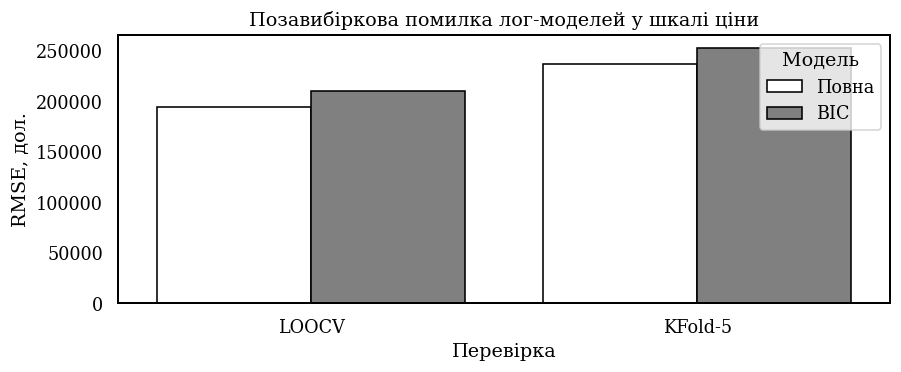

In [14]:
def evaluate_cv(splitter, transform):
    truth = np.log(y) if transform == "log" else y
    predictions = {"Повна": np.empty(len(y)), "BIC": np.empty(len(y)),
                   "Середнє": np.empty(len(y))}
    sizes, folds = [], []
    for train_ix, valid_ix in splitter.split(X):
        train_x, valid_x = X.iloc[train_ix], X.iloc[valid_ix]
        train_y = truth[train_ix]
        chosen, _, _ = backward_bic(train_x, y[train_ix], groups)
        sizes.append(len(chosen))
        for label, cols in [("Повна", list(X.columns)), ("BIC", chosen)]:
            features = [c for c in cols if c != "Intercept"]
            model = LinearRegression().fit(train_x[features], train_y)
            estimate = model.predict(valid_x[features])
            if transform == "log":
                train_resid = train_y - model.predict(train_x[features])
                estimate = np.exp(estimate) * np.mean(np.exp(train_resid))
            predictions[label][valid_ix] = estimate
        predictions["Середнє"][valid_ix] = y[train_ix].mean()
        folds.append(valid_ix)
    rows = []
    for label, prediction in predictions.items():
        assert np.isfinite(prediction).all()
        mse = mean_squared_error(y, prediction)
        fold_rmse = [np.sqrt(mean_squared_error(y[ix], prediction[ix]))
                     for ix in folds]
        rows.append({"Модель": label, "Ціль": transform, "MSE, дол.²": mse,
                     "RMSE, дол.": np.sqrt(mse),
                     "Середня к-ть параметрів": np.mean(sizes) if label == "BIC"
                     else (len(X.columns) if label == "Повна" else 1),
                     "SD RMSE блоків": np.std(fold_rmse, ddof=1)
                     if len(folds) == 5 else np.nan})
    return pd.DataFrame(rows), predictions

cv_tables, cv_predictions = [], {}
for name, splitter in [("LOOCV", LeaveOneOut()),
                        ("KFold-5", KFold(5, shuffle=True, random_state=SEED))]:
    for target in ["level", "log"]:
        table, predictions = evaluate_cv(splitter, target)
        table.insert(0, "Перевірка", name)
        cv_tables.append(table)
        cv_predictions[(name, target)] = predictions
cv = pd.concat(cv_tables, ignore_index=True)
display(cv.drop(columns=["SD RMSE блоків"]).round(2))
print("Розкид між п'ятьма блоками, RMSE у доларах:")
display(cv.loc[(cv["Перевірка"] == "KFold-5") & (cv["Модель"] != "Середнє"),
               ["Модель", "Ціль", "RMSE, дол.", "SD RMSE блоків"]].round(2))

bad_predictions = pd.DataFrame({
    "Id": sample["Id"].to_numpy(), "Справжня ціна": y,
    "LOO, log": cv_predictions[("LOOCV", "log")]["BIC"],
    "LOO, рівні": cv_predictions[("LOOCV", "level")]["BIC"]
})
log_sq_error = (bad_predictions["LOO, log"] - y)**2
worst = log_sq_error.idxmax()
display(bad_predictions.loc[log_sq_error.nlargest(3).index].round(2))
results.update(worst_id=int(bad_predictions.loc[worst, "Id"]),
               worst_log=bad_predictions.loc[worst, "LOO, log"],
               worst_true=bad_predictions.loc[worst, "Справжня ціна"],
               worst_share=100*log_sq_error.max()/log_sq_error.sum())

log_cv = cv[(cv["Ціль"] == "log") & (cv["Модель"] != "Середнє")]
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.barplot(data=log_cv, x="Перевірка", y="RMSE, дол.", hue="Модель", palette=["white", "0.5"], edgecolor="black", ax=ax)
ax.set_title("Позавибіркова помилка лог-моделей у шкалі ціни")
plt.tight_layout()
plt.show()
for split_name, short in [("LOOCV", "loo"), ("KFold-5", "kf")]:
    for label, tag in [("Повна", "full"), ("BIC", "bic"), ("Середнє", "mean")]:
        row = cv[(cv["Перевірка"] == split_name) & (cv["Ціль"] == "log")
                 & (cv["Модель"] == label)].iloc[0]
        results[f"{short}_{tag}_mse"] = row["MSE, дол.²"]
        results[f"{short}_{tag}_rmse"] = row["RMSE, дол."]

Найнижча MSE — у повної моделі в рівнях: LOO RMSE=55128.13 дол., KFold RMSE=57022.40 дол. Скорочена модель у рівнях близька за якістю.
Лог-модель нестійка: Id=1299 має LOO-прогноз 7182929.39 дол. за ціни 160000 дол. та 93.41% суми її квадратів помилок.
Отже, результат тесту трансформації не гарантує кращої доларової MSE. Для прогнозу обираю повну модель в рівнях.

# Задача 6. Нелінійна регресія

## (а) Лінійна та (б) експоненціальна моделі

Використовую перші 500 початкових рядків.
$P=a+b(YearBuilt-1900)+u$;
$P=A\exp[b(YearBuilt-1900)/100]+u$.
NLS оцінюється curve_fit у шкалі ціни; центрування покращує числову стійкість.

,Модель,R²,"MSE, дол.²"
0,Лінійна,0.3030,4.2974e+09
1,Експоненціальна NLS,0.3436,4.0477e+09


Лінійна: P = 79355.14 + 1447.76 × (YearBuilt − 1900)
NLS: P = 87868.18 × exp(0.96571 × (YearBuilt − 1900)/100)
MSE з трьох стартових точок: [4047673152.34, 4047673152.63, 4047673152.36]


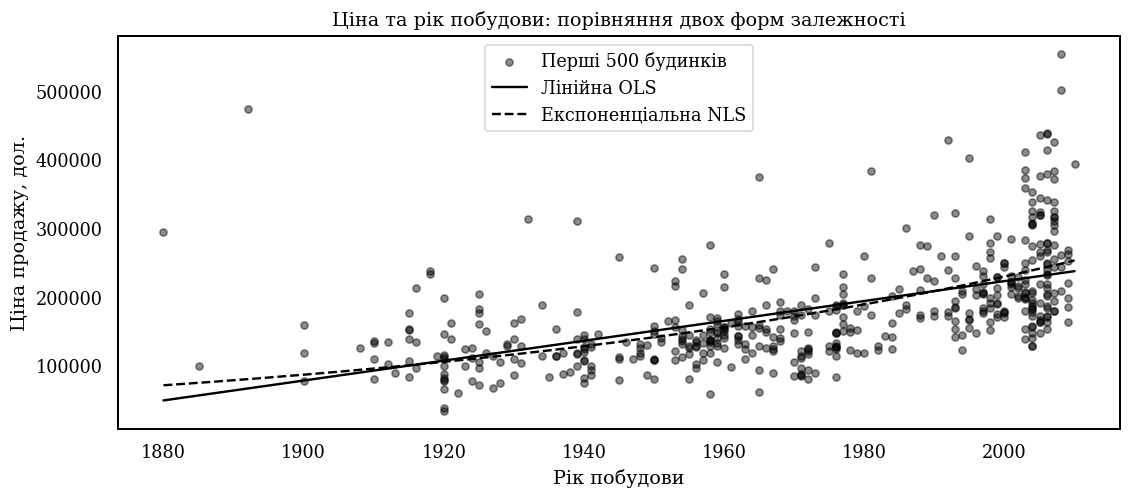

In [15]:
first500 = df.iloc[:500].copy()
assert len(first500) == 500
years = first500["YearBuilt"].to_numpy(dtype=float)
price500 = first500["SalePrice"].to_numpy(dtype=float)
age_centered = years - 1900
time100 = age_centered / 100
linear500 = sm.OLS(price500, sm.add_constant(age_centered)).fit()

def exponential(t, A, b):
    return A * np.exp(b * t)

solutions = []
for start_b in [-0.5, 0.5, 1.5]:
    params, covariance = curve_fit(
        exponential, time100, price500, p0=[100000, start_b],
        bounds=([1, -5], [1000000, 5]), maxfev=20000,
        x_scale=[100000, 1]
    )
    solutions.append((mean_squared_error(price500, exponential(time100, *params)),
                      params, covariance))
_, params, covariance = min(solutions, key=lambda item: item[0])
pred_lin = linear500.predict(sm.add_constant(age_centered))
pred_nls = exponential(time100, *params)
fit500 = pd.DataFrame({
    "Модель": ["Лінійна", "Експоненціальна NLS"],
    "R²": [r2_score(price500, pred_lin), r2_score(price500, pred_nls)],
    "MSE, дол.²": [mean_squared_error(price500, pred_lin),
                    mean_squared_error(price500, pred_nls)]
})
display(fit500)
print(f"Лінійна: P = {linear500.params[0]:.2f} + "
      f"{linear500.params[1]:.2f} × (YearBuilt − 1900)")
print(f"NLS: P = {params[0]:.2f} × exp({params[1]:.5f} × (YearBuilt − 1900)/100)")
print("MSE з трьох стартових точок:", [round(s[0], 2) for s in solutions])

grid = np.linspace(years.min(), years.max(), 300)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(years, price500, s=20, alpha=.45, label="Перші 500 будинків")
ax.plot(grid, linear500.predict(sm.add_constant(grid-1900)),
        lw=1.5, color="black", label="Лінійна OLS")
ax.plot(grid, exponential((grid-1900)/100, *params),
        lw=1.5, color="black", ls="--", label="Експоненціальна NLS")
ax.set(xlabel="Рік побудови", ylabel="Ціна продажу, дол.",
       title="Ціна та рік побудови: порівняння двох форм залежності")
ax.legend()
plt.tight_layout()
plt.show()
results.update(nls_A=params[0], nls_b=params[1],
               lin500_r2=fit500.loc[0, "R²"], nls_r2=fit500.loc[1, "R²"],
               lin500_mse=fit500.loc[0, "MSE, дол.²"],
               nls_mse=fit500.loc[1, "MSE, дол.²"],
               nls_gain=100*(1-fit500.loc[1, "MSE, дол.²"]/fit500.loc[0, "MSE, дол.²"]))

NLS зменшує навчальну MSE на 5.8117%; R² зростає з 0.303048 до 0.343553. Три стартові точки дали практично однаковий мінімум.

## (в) Статистичні висновки для NLS

Оцінки нелінійно залежать від даних, тому точний маловибірковий t-розподіл не гарантований.
Коваріація curve_fit — локальне наближення $\widehat\sigma^2(J'J)^{-1}$; потрібні асимптотичні методи чи bootstrap.

## (г) Збіжність і перенавчання

Можливі локальні мінімуми, залежність від старту, нестійкий Якобіан і колінеарність.
За 500 рядків велика кількість параметрів сприяє перенавчанню. Допомагають масштабування, межі, кілька стартів, регуляризація та крос-валідація.

In [16]:
import importlib.metadata as metadata
print("Python:", sys.version.split()[0])
for package in ["numpy", "pandas", "scipy", "statsmodels", "scikit-learn",
                "matplotlib", "seaborn"]:
    print(f"{package}: {metadata.version(package)}")

Python: 3.11.9
numpy: 2.4.6
pandas: 3.0.6
scipy: 1.17.1
statsmodels: 0.15.0
scikit-learn: 1.9.1
matplotlib: 3.10.9
seaborn: 0.13.2
